<!-- d2l:prose id=convergence-md-1 fw=all -->

# Gradient Penalties and Convergence

In the Fashion-MNIST experiment of that section, neither the discriminator loss nor the generator loss settled to its theoretical equilibrium value. Does alternating gradient descent converge slowly, or can it orbit an equilibrium indefinitely without reaching it? The population divergence analyses of that section–that section characterize the minimax objective when the critic is at its exact optimum $D^\star$, but in practice both networks take small simultaneous or alternating gradient steps, with each update shifting the other network's objective.

To analyze the dynamics of gradient training directly, @Mescheder.Geiger.Nowozin.2018 introduced the *Dirac-GAN*—a minimal two-parameter problem consisting of a point-mass data distribution, a point-mass generator, and a linear critic. Even on this two-parameter system, unregularized gradient descent fails to converge, whereas penalizing the squared norm of the critic's input gradient ($R_1$ and $R_2$) makes the equilibrium locally asymptotically stable. Combining these zero-centered gradient penalties with the relativistic pairing objective of that section yields the R3GAN recipe [@Huang.Gokaslan.Kuleshov.ea.2024] used across the remainder of this chapter.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

<!-- d2l:prose id=convergence-md-2 fw=all -->

## The Dirac-GAN

### A Two-Parameter Minimax System

Let the data distribution be a point mass at the origin, $p = \delta_0$, let the generator place a point mass at $\theta \in \mathbb{R}$, $q_\theta = \delta_\theta$ (so $q_\theta = p$ if and only if $\theta = 0$), and let the critic be linear without bias, $D_\psi(x) = \psi x$. Under the symmetric margin objective $V_\ell(D) = \mathbb{E}_{x \sim p}[\ell(D(x))] + \mathbb{E}_{x' \sim q}[\ell(-D(x'))]$ (that section), both expectations reduce to single evaluations:

$$
\begin{aligned}
V(\theta, \psi) &= \ell\big(D_\psi(0)\big) + \ell\big({-D_\psi(\theta)}\big) \\
&= \ell(0) + \ell(-\psi\theta).
\end{aligned}
$$

We take the logistic payoff $\ell(t) = \log \sigma(t)$, which satisfies $\ell'(t) = \sigma(-t) > 0$ and $\ell''(t) = -\sigma(t)\sigma(-t) < 0$, with $\ell'(0) = \tfrac12$ and $\ell''(0) = -\tfrac14$.

For any $\theta \neq 0$, the supports of $p$ and $q_\theta$ are disjoint: maximizing $V(\theta, \psi)$ over $\psi$ sends $\psi\theta \to -\infty$, yielding the constant $\sup_\psi V(\theta, \psi) = \ell(0)$ for all $\theta \neq 0$, which provides zero gradient with respect to $\theta$.

### Undamped Oscillations in Continuous Time

Instead of solving for $\sup_\psi V(\theta, \psi)$, gradient training updates $\theta$ and $\psi$ incrementally from their current values. The unique stationary point of the equation is the equilibrium $(\theta, \psi) = (0, 0)$. Under simultaneous continuous-time gradient flow ($\dot\theta = -\partial_\theta V$, $\dot\psi = +\partial_\psi V$),

$$
\begin{aligned}
\dot\theta &= -\partial_\theta V = \psi\, \ell'(-\psi\theta), \\
\dot\psi &= +\partial_\psi V = -\theta\, \ell'(-\psi\theta).
\end{aligned}
$$

Because the velocity vector $\mathbf{u}(\theta, \psi) = \ell'(-\psi\theta)\,(\psi, -\theta)$ is everywhere orthogonal to the state vector $(\theta, \psi)$, the squared distance to the origin is conserved:

$$
\begin{aligned}
\frac{d}{dt}\big(\theta^2 + \psi^2\big)
&= 2\theta\psi\,\ell'(-\psi\theta) - 2\psi\theta\,\ell'(-\psi\theta) = 0 .
\end{aligned}
$$

Every trajectory is a closed circle of constant radius around $(0, 0)$ for any strictly increasing payoff $\ell$: the generator parameter $\theta$ oscillates back and forth across $0$ without ever converging.

Linearizing the equation around $(\theta, \psi) = (0, 0)$ (that section) yields the Jacobian matrix and eigenvalues:

$$
J = \begin{pmatrix} 0 & \ell'(0) \\ -\ell'(0) & 0 \end{pmatrix},
\qquad
\nu_{1,2} = \pm\, i\, \ell'(0).
$$

Purely imaginary eigenvalues correspond to a linear *center* (the bilinear saddle problem $\min_\theta \max_\psi \theta\psi$, @Daskalakis.Ilyas.Syrgkanis.ea.2018). Notice that the scalar factor $\ell'(-\psi\theta) = \sigma(D_\psi(\theta)) = w_{\textrm{sat}}$ multiplies both components simultaneously and therefore only rescales angular velocity along the circle.

### Outward Spirals and Limit Cycles in Discrete Time

In discrete time, simultaneous gradient descent with step size $h > 0$ updates $(\theta, \psi) \mapsto (\theta, \psi) + h\,\mathbf{u}(\theta, \psi)$. Because $\mathbf{u}(\theta, \psi) \perp (\theta, \psi)$, the Pythagorean theorem gives:

$$
\begin{aligned}
\big\| (\theta, \psi) + h\, \mathbf{u} \big\|^2
&= \big\| (\theta, \psi) \big\|^2 + h^2 \big\| \mathbf{u} \big\|^2 .
\end{aligned}
$$

Thus, every simultaneous discrete step strictly *increases* the distance from the equilibrium for any $h > 0$, causing the iterates to spiral outward (Exercise 1).

Alternating gradient updates (updating $\psi$ first, then $\theta$ using the updated $\psi$) fare slightly better: near $(0, 0)$, each half-step is an area-preserving linear shear, so the composite Jacobian has determinant $1$. For $h\,\ell'(0) \leq 2$, both eigenvalues lie on the unit circle [@Mescheder.Geiger.Nowozin.2018], so alternating iterates orbit within a bounded band around the origin without converging (Exercise 4). Neither the non-saturating generator loss (which shares the same linearization $J$ at the origin) nor the relativistic pairing loss ($\ell(D_\psi(0) - D_\psi(\theta)) = \ell(-\psi\theta)$, which has the identical gradient field) alters these local eigenvalues.

## Zero-Centered Gradient Penalties

To make the equilibrium $(\theta, \psi) = (0, 0)$ locally asymptotically stable, we must shift the eigenvalues of the Jacobian from the imaginary axis into the open left half-plane $\operatorname{Re}(\nu) < 0$. Because the equilibrium critic must be flat ($\nabla_x D^\star(x) = 0$ when $q = p$), penalizing the squared norm of the critic's input gradient adds damping to the critic without shifting the equilibrium $q = p$.

@Mescheder.Geiger.Nowozin.2018 define the two *zero-centered gradient penalties* $R_1$ (evaluated on real data $x \sim p$) and $R_2$ (evaluated on generated samples $x' \sim q$):

$$
\begin{aligned}
R_1 &= \frac{\gamma}{2}\, \mathbb{E}_{x \sim p}\Big[ \big\| \nabla_x D(x) \big\|^2 \Big], \\
R_2 &= \frac{\gamma}{2}\, \mathbb{E}_{x' \sim q}\Big[ \big\| \nabla_{x'} D(x') \big\|^2 \Big],
\end{aligned}
$$

with penalty weight $\gamma > 0$. The critic maximizes $V_\ell(D) - R_1 - R_2$, while the generator objective is unchanged. Writing $m = (p + q)/2$, their sum is the expected squared gradient norm under the mixture distribution:

$$
\begin{aligned}
R_1 + R_2 &= \gamma\, \mathbb{E}_{x \sim m}\Big[ \big\| \nabla_x D(x) \big\|^2 \Big],
\qquad m = \frac{p + q}{2}.
\end{aligned}
$$

### Damping the Dirac-GAN

For the linear critic $D_\psi(x) = \psi x$, we have $\nabla_x D_\psi(x) = \psi$ everywhere, so $R_1 = R_2 = \tfrac{\gamma}{2}\psi^2$. Subtracting $\tfrac{\gamma}{2}\psi^2$ from the critic objective adds a linear damping term $-\gamma\psi$ to $\dot\psi$ (or $-2\gamma\psi$ if both $R_1$ and $R_2$ are included):

$$
\dot\theta = \psi\,\ell'(-\psi\theta),
\qquad
\dot\psi = -\theta\,\ell'(-\psi\theta) - \gamma\psi .
$$

The Jacobian at $(0, 0)$ and its eigenvalues become:

$$
J_\gamma = \begin{pmatrix} 0 & \ell'(0) \\ -\ell'(0) & -\gamma \end{pmatrix},
\qquad
\nu_{1,2} \;=\; -\frac{\gamma}{2} \pm \sqrt{ \frac{\gamma^2}{4} - \ell'(0)^2 } .
$$

For every $\gamma > 0$, both eigenvalues have strictly negative real part ($\operatorname{Re}(\nu_{1,2}) < 0$), so the equilibrium $(0, 0)$ is locally exponentially stable. The characteristic polynomial $\nu^2 + \gamma\nu + \ell'(0)^2 = 0$ is identical to that of a damped harmonic oscillator (that section) with three regimes:

1. *Underdamped* ($\gamma < 2\ell'(0)$): complex-conjugate eigenvalues with real part $-\gamma/2$; trajectories spiral inward (converging under simultaneous Euler steps when $h < \gamma / \ell'(0)^2$, Exercise 1).
2. *Critically damped* ($\gamma = 2\ell'(0)$, i.e., $\gamma = 1$ for the logistic loss): repeated real eigenvalue $\nu = -\ell'(0)$, yielding the fastest non-oscillatory decay.
3. *Overdamped* ($\gamma > 2\ell'(0)$): two negative real eigenvalues, where the slow mode $\nu \approx -\ell'(0)^2/\gamma$ decays more slowly as $\gamma$ increases.

### Phase Portraits

We verify these four regimes by integrating the equation from $(\theta_0, \psi_0) = (1, 1)$ (initial radius $\sqrt{2} \approx 1.41$) using fourth-order Runge–Kutta (`rk4_step`), simultaneous forward Euler (`euler_step`), and alternating gradient updates (`alt_step`).

In [2]:
def dirac_field(theta, psi, gamma=0.0):
    """Simultaneous gradient field of the Dirac-GAN with the logistic loss."""
    w = 1.0 / (1.0 + np.exp(-psi * theta))      # l'(-psi theta) = w_sat
    return np.array([psi * w, -theta * w - gamma * psi])

def euler_step(x, h, gamma):                     # one simultaneous step
    return x + h * dirac_field(*x, gamma)

def alt_step(x, h, gamma):                       # critic first, then generator
    theta, psi = x
    psi = psi + h * dirac_field(theta, psi, gamma)[1]
    return np.array([theta + h * dirac_field(theta, psi, gamma)[0], psi])

def rk4_step(x, h, gamma):                       # one RK4 step of the ODE
    k1 = dirac_field(*x, gamma)
    k2 = dirac_field(*(x + h / 2 * k1), gamma)
    k3 = dirac_field(*(x + h / 2 * k2), gamma)
    k4 = dirac_field(*(x + h * k3), gamma)
    return x + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

def trajectory(step, x0, h, steps, gamma=0.0):
    xs = [np.array(x0)]
    for _ in range(steps):
        xs.append(step(xs[-1], h, gamma))
    return np.stack(xs)

<!-- d2l:prose id=convergence-md-3 fw=all -->

All paths start at the red dot, $(\theta, \psi) = (1, 1)$, at distance $\sqrt 2 \approx 1.41$ from the equilibrium at the black cross. The left panel shows the flow. The middle panel shows 300 simultaneous and 2,000 alternating steps of size $h = 0.2$. The right panel shows 300 simultaneous steps of the same size with the penalty, at $\gamma = 0.3$ in the underdamped regime and at the critical $\gamma = 1$.

flow, RK4: 1.41 -> 1.41 in 800 steps; second half in [1.41, 1.41]
steps, simultaneous: 1.41 -> 2.87 in 300 steps; second half in [2.44, 2.87]
steps, alternating: 1.41 -> 1.36 in 2000 steps; second half in [1.34, 1.42]
penalized, gamma = 0.3: 1.41 -> 0.000652 in 300 steps; second half in [0.000652, 0.0396]
penalized, gamma = 1: 1.41 -> 6.97e-12 in 300 steps; second half in [6.97e-12, 2.33e-05]


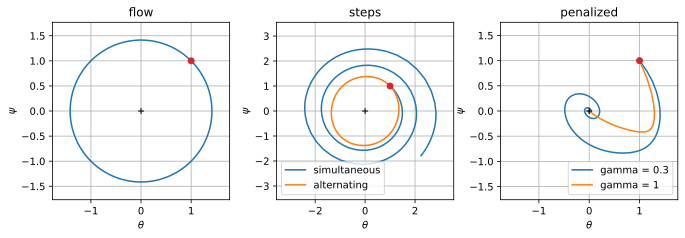

In [3]:
x0 = np.array([1.0, 1.0])
panels = {'flow': {'RK4': trajectory(rk4_step, x0, 0.05, 800)},
          'steps': {'simultaneous': trajectory(euler_step, x0, 0.2, 300),
                    'alternating': trajectory(alt_step, x0, 0.2, 2000)},
          'penalized': {
              'gamma = 0.3': trajectory(euler_step, x0, 0.2, 300, gamma=0.3),
              'gamma = 1': trajectory(euler_step, x0, 0.2, 300, gamma=1.0)}}
fig, axes = d2l.plt.subplots(1, 3, figsize=(9.5, 3.4))
for ax, (title, paths) in zip(axes, panels.items()):
    for name, P in paths.items():
        r = np.linalg.norm(P, axis=1)            # distance to the equilibrium
        late = r[len(r) // 2:]
        print(f'{title}, {name}: {r[0]:.3g} -> {r[-1]:.3g} in {len(r) - 1} '
              f'steps; second half in [{late.min():.3g}, {late.max():.3g}]')
    lim = 1.25 * max(np.abs(P).max() for P in paths.values())
    d2l.plot([P[:, 0] for P in paths.values()] + [x0[:1], [0.0]],
             [P[:, 1] for P in paths.values()] + [x0[1:], [0.0]],
             r'$\theta$', r'$\psi$', list(paths) if len(paths) > 1 else None,
             xlim=(-lim, lim), ylim=(-lim, lim), axes=ax,
             fmts=('C0-', 'C1-')[:len(paths)] + ('C3o', 'k+'),
             legend_loc='lower right' if title == 'penalized' else None)
    ax.set_title(title)
    ax.set_aspect('equal')
fig.tight_layout()

<!-- d2l:prose id=convergence-md-4 fw=all -->

The phase portraits confirm all four predictions: the continuous flow (`RK4`) orbits on the circle of radius $1.41$, simultaneous Euler steps spiral outward to radius $2.87$ after 300 steps, alternating steps orbit inside $[1.34, 1.42]$, and adding the zero-centered penalty drives simultaneous Euler steps directly to the origin ($6.5 \times 10^{-4}$ at underdamped $\gamma = 0.3$, and $7 \times 10^{-12}$ at critically damped $\gamma = 1$).

### Local Convergence for General Networks and Comparison of Penalties

@Mescheder.Geiger.Nowozin.2018 extended this local stability analysis from the two-parameter Dirac-GAN to general neural networks: near an equilibrium where the generator represents the data distribution $p$ and the critic is flat on $\operatorname{supp}(p)$, simultaneous and alternating gradient updates with $R_1$ or $R_2$ (and a strictly concave loss satisfying $\ell'(0) \neq 0, \ell''(0) < 0$) converge exponentially to the equilibrium manifold, provided the critic has sufficient local capacity to detect first-order generator perturbations (@Huang.Gokaslan.Kuleshov.ea.2024 establish an analogous local theorem for the relativistic pairing objective).

This analysis also explains two practical design choices:

- **Zero-centered ($R_1, R_2$) vs. one-centered (WGAN-GP) penalties:** WGAN-GP penalizes $(\|\nabla_x D\| - 1)^2$, forcing the critic to maintain unit slope even when $q = p$. On the Dirac-GAN with linear payoff $\ell(t) = t$, the one-centered penalty prevents convergence to $\theta = 0$. For $\gamma \geq 2$ it parks the generator at $|\theta| = \gamma$, where the Wasserstein gradient balances the penalty; for smaller $\gamma$ the generator overshoots this point and keeps cycling (Exercise 6).
- **Using both $R_1$ and $R_2$ vs. $R_1$ alone:** Near $q = p$, $R_1$ and $R_2$ are equivalent. Far from equilibrium, however, $R_1$ penalizes the critic's slope only at real data points $x \sim p$, leaving its slope at generated points $x' \sim q$ unconstrained (for example, $D_c(x) = -cx^2$ has zero slope at $p = \delta_0$ so $R_1 = 0$, allowing $c \to \infty$ and exploding generator gradients at $x' = 1$; Exercise 3). Adding $R_2$ bounds the critic's gradient at generated samples as well.

## Effect of Gradient Penalties on the Value Function

How do the zero-centered penalties $R_1 + R_2 = \gamma\,\mathbb{E}_m[\|\nabla_x D\|^2]$ modify the divergence that the generator minimizes near equilibrium?

### Local Quadratic Approximation and Gaussian Shift

Near $q = p$, the optimal critic $D$ is small. Expanding $\ell(t) \approx \ell(0) + \ell'(0)t - \tfrac12|\ell''(0)|t^2$ to second order in $D$ inside $V_\ell(D)$ gives:

$$
\begin{aligned}
V_\ell(D) &\approx 2\ell(0) + \ell'(0)\, \langle p - q,\, D \rangle - |\ell''(0)| \int m\, D^2 ,
\end{aligned}
$$

where $\langle p - q, D \rangle = \mathbb{E}_p[D] - \mathbb{E}_q[D]$. Consider two unit-variance Gaussians $p = \mathcal{N}(0, 1)$ and $q = \mathcal{N}(\mu, 1)$ separated by a small shift $\mu$, and a linear critic $D(x) = cx$. To leading order in $\mu$, $\langle p - q, D \rangle = -c\mu$, $\int m\,D^2 \approx c^2$, and the penalty is $\gamma\int m\,\|\nabla_x D\|^2 = \gamma c^2$. Maximizing the concave quadratic $-\ell'(0)\mu c - (|\ell''(0)| + \gamma)c^2$ over $c$ yields the optimal slope $c^\star = -\frac{\ell'(0)\mu}{2(|\ell''(0)| + \gamma)}$ and value:

$$
\begin{aligned}
\frac{\ell'(0)^2 \mu^2}{4\,(|\ell''(0)| + \gamma)} &= \frac{\mu^2}{4 + 16\gamma} \\
&\text{for the logistic loss, at slope } c^\star = -\frac{\mu}{1 + 4\gamma} .
\end{aligned}
$$

Thus, the penalty shrinks both the critic's slope and the local value by the factor $1 + 4\gamma$. At $\gamma = 0$, we recover $\mu^2/4 \approx 2\,\mathrm{JS}(p, q)$; for large $\gamma$, the value scales as $\mu^2/(16\gamma) = \tfrac{\ell'(0)^2}{4\gamma} W_2(p, q)^2$. Below, we verify this closed-form approximation against the exact penalized optimum computed via Newton's method on a 1D grid.

In [4]:
def penalized_value(p, q, gamma, x, newton_steps=30):
    """Value of the logistic game minus gamma E_m[D'^2], on a grid."""
    dx, m = x[1] - x[0], (p + q) / 2
    diff = np.diff(np.eye(len(x)), axis=0) / dx       # D -> D'
    K = 2 * gamma * dx * diff.T @ (((m[1:] + m[:-1]) / 2)[:, None] * diff)
    D = np.zeros_like(x)
    for _ in range(newton_steps):                     # Newton ascent on D
        s = 1 / (1 + np.exp(-D))                      # sigma(D)
        grad = (p * (1 - s) - q * s) * dx - K @ D     # gradient of the value
        neg_hess = np.diag(2 * m * s * (1 - s) * dx) + K  # minus its Hessian
        D = D + np.linalg.solve(neg_hess, grad)
    value = -(p * np.logaddexp(0, -D) + q * np.logaddexp(0, D)).sum() * dx
    return value - D @ K @ D / 2 + 2 * np.log(2)       # minus 2 l(0)

x = np.linspace(-8, 8, 401)
for mu in (0.2, 1, 3):
    p, q = [np.exp(-(x - c) ** 2 / 2) / np.sqrt(2 * np.pi) for c in (0, mu)]
    for gamma in (0, 0.01, 1, 10):
        exact = penalized_value(p, q, gamma, x)
        local = mu ** 2 / (4 + 16 * gamma)
        large = mu ** 2 / (16 * gamma) if gamma else np.inf
        print(f'mu {mu:>3}, gamma {gamma:>4}: exact {exact:.3e}, local '
              f'{local:.3e} ({local / exact:.2f}x), large-gamma {large:.3e} '
              f'({large / exact:.2f}x)')

mu 0.2, gamma    0: exact 9.950e-03, local 1.000e-02 (1.00x), large-gamma inf (infx)
mu 0.2, gamma 0.01: exact 9.566e-03, local 9.615e-03 (1.01x), large-gamma 2.500e-01 (26.13x)
mu 0.2, gamma    1: exact 1.996e-03, local 2.000e-03 (1.00x), large-gamma 2.500e-03 (1.25x)
mu 0.2, gamma   10: exact 2.438e-04, local 2.439e-04 (1.00x), large-gamma 2.500e-04 (1.03x)


mu   1, gamma    0: exact 2.228e-01, local 2.500e-01 (1.12x), large-gamma inf (infx)
mu   1, gamma 0.01: exact 2.135e-01, local 2.404e-01 (1.13x), large-gamma 6.250e+00 (29.27x)
mu   1, gamma    1: exact 4.818e-02, local 5.000e-02 (1.04x), large-gamma 6.250e-02 (1.30x)
mu   1, gamma   10: exact 6.120e-03, local 6.098e-03 (1.00x), large-gamma 6.250e-03 (1.02x)


mu   3, gamma    0: exact 1.054e+00, local 2.250e+00 (2.14x), large-gamma inf (infx)
mu   3, gamma 0.01: exact 1.012e+00, local 2.163e+00 (2.14x), large-gamma 5.625e+01 (55.57x)
mu   3, gamma    1: exact 3.909e-01, local 4.500e-01 (1.15x), large-gamma 5.625e-01 (1.44x)
mu   3, gamma   10: exact 6.862e-02, local 5.488e-02 (0.80x), large-gamma 5.625e-02 (0.82x)


<!-- d2l:prose id=convergence-md-5 fw=all -->

For small shifts ($\mu = 0.2$), the quadratic formula $\mu^2/(4 + 16\gamma)$ matches the exact numerical solution to within 1% across all $\gamma$.

### Dual Sobolev Norm and Low-Pass Filtering

For general distributions $p$ and $q$ near equilibrium, integrating by parts writes the gradient penalty as $\int m\,\|\nabla_x D\|^2 = \langle D, \mathcal{L}_m D \rangle$, where $\mathcal{L}_m D = -\nabla \cdot (m \nabla D)$ is the $m$-weighted Laplacian. Maximizing the local quadratic approximation over all functions $D$ yields (Exercise 5):

$$
\begin{aligned}
&\sup_{D} \Big\{ \ell'(0)\, \langle p - q,\, D \rangle - |\ell''(0)| \int m\, D^2 - \gamma \int m\, \| \nabla_x D \|^2 \Big\} \\
&\qquad = \frac{\ell'(0)^2}{4}\, \big\langle p - q,\, \big(|\ell''(0)|\, m + \gamma \mathcal{L}_m\big)^{-1} (p - q) \big\rangle .
\end{aligned}
$$

As $\gamma \to 0$, this reduces to $\tfrac{\ell'(0)^2}{4|\ell''(0)|} \int (p - q)^2/m \approx 2\,\mathrm{JS}(p, q)$. As $\gamma \to \infty$, it approaches a multiple of the squared *dual Sobolev norm* $\dot H^{-1}(m)$:

$$
\begin{aligned}
&\frac{\ell'(0)^2}{4\gamma}\, \big\| p - q \big\|^2_{\dot H^{-1}(m)}, \\
&\|v\|_{\dot H^{-1}(m)} = \sup\Big\{ \langle v, D\rangle : \int m \|\nabla_x D\|^2 \leq 1 \Big\}.
\end{aligned}
$$

In regions where $m$ is approximately uniform, $\mathcal{L}_m$ multiplies a Fourier mode of wavenumber $\omega$ by $m\omega^2$, weighting that mode by $(|\ell''(0)| + \gamma\omega^2)^{-1}$ instead of $|\ell''(0)|^{-1}$. Thus, $R_1 + R_2$ acts as a spatial *low-pass filter* on $p - q$ with cutoff length scale $\sqrt{\gamma / |\ell''(0)|}$ ($2\sqrt{\gamma}$ for the logistic loss). Because $\nabla_x D$ has units of inverse length, $\gamma$ has units of squared length and scales with data resolution and norm. Note also that $R_1 + R_2$ penalizes $\nabla_x D$ only on the support of $m = (p+q)/2$; across empty space between disjoint supports, the gradient still relies on the smoothness of the neural network critic (Exercise 2).

## The R3GAN Recipe

R3GAN [@Huang.Gokaslan.Kuleshov.ea.2024] combines the relativistic pairing loss (`d2l.rpgan_loss_D` and `d2l.rpgan_loss_G` from that section) with both zero-centered gradient penalties $R_1$ and $R_2$.

### Implementation of the Losses and Penalties

For comparison, we also save `gan_loss_D` and `gan_loss_G` implementing the classic logistic discriminator loss and non-saturating generator loss of that section with the same `(critic, real, fake)` signature.

In [5]:

def gan_loss_D(critic, real, fake):
    """Logistic critic loss -E[log sigma(D(x))] - E[log sigma(-D(x'))]: the
    sum of two batch means, 2 log 2 at equilibrium, as update_D."""
    return F.softplus(-critic(real)).mean() + F.softplus(critic(fake)).mean()


def gan_loss_G(critic, real, fake):
    """Non-saturating generator loss -E[log sigma(D(x'))]; real is unused."""
    return F.softplus(-critic(fake)).mean()

<!-- d2l:prose id=convergence-md-6 fw=all -->

The penalty function returns the per-sample squared input gradients on both batches, before the factor $\gamma/2$. It differentiates the *sum* of the critic's scores with respect to the input batch: each score depends only on its own row, so one backward pass gives every sample's input gradient (batch normalization, which mixes rows, would break this). The input gradient stays in the autodiff graph, so the optimizer can differentiate the penalty with respect to the critic's parameters. The samples are held constant. The second differentiation makes a penalized critic step cost roughly two backward passes.

<!-- d2l:prose id=convergence-md-7 fw=pytorch -->

`create_graph=True` keeps the graph of the input gradient for the second differentiation, and `detach` makes the samples constants.

In [6]:

def r1_r2_penalty(critic, real, fake):
    """Per-sample squared critic input gradients on real (R1) and fake (R2),
    before the gamma/2 scale."""
    def sq_grad_norm(x):
        x = x.detach().requires_grad_(True)
        grad, = torch.autograd.grad(critic(x).sum(), x, create_graph=True)
        return grad.reshape(x.shape[0], -1).pow(2).sum(dim=1)
    return sq_grad_norm(real), sq_grad_norm(fake)

<!-- d2l:prose id=convergence-md-8 fw=all -->

### The Training Steps

A training loop alternates one step of each player. `critic_step` takes one optimizer step on the critic loss plus $\gamma/2$ times both penalties, with the generated batch held fixed, and returns the loss and the batch means of the squared input gradients at real and generated samples ($R_1$ and $R_2$ before the factor $\gamma/2$), so that a loop can log the critic's steepness. `generator_step` then takes one step on the generator loss against the updated critic. The optional labels `y` serve the conditional critic of that section.

In [7]:

def critic_step(net_D, opt_D, loss_D, real, fake, gamma, y=None):
    """One critic step on loss_D + gamma/2 (R1 + R2); return the loss and
    the batch means of R1 and R2."""
    critic = net_D if y is None else lambda x: net_D(x, y)
    fake = fake.detach()  # the generator is held fixed
    r1, r2 = r1_r2_penalty(critic, real, fake)
    loss = loss_D(critic, real, fake)
    opt_D.zero_grad()
    (loss + gamma / 2 * (r1 + r2).mean()).backward()
    opt_D.step()
    return loss.detach(), r1.mean().detach(), r2.mean().detach()


def generator_step(net_G, opt_G, loss_G, net_D, real, z, y=None):
    """One generator step on loss_G against the critic; return the loss."""
    critic = net_D if y is None else lambda x: net_D(x, y)
    loss = loss_G(critic, real, net_G(z) if y is None else net_G(z, y))
    opt_G.zero_grad()
    loss.backward()
    opt_G.step()
    return loss.detach()

<!-- d2l:prose id=convergence-md-9 fw=all -->

### Mode Coverage on a 25-Gaussian Grid

To test how $R_1 + R_2$ and pairwise ranking affect mode coverage in neural networks, we train a 3-layer MLP generator (64D latent, two hidden layers of 256 ReLU units) and a 3-layer leaky-ReLU MLP critic on a $5 \times 5$ grid of 2D Gaussians (spacing $2.0$, standard deviation $\sigma = 0.05$). We evaluate 10,000 generated samples by four metrics:

1. *Covered modes*: number of modes receiving at least $1/5$ of an equal share ($1/25$) of on-mode samples.
2. *On-mode fraction*: fraction of samples within $3\sigma = 0.15$ of the nearest mode center ($98.9\%$ for the true distribution).
3. *Mean distance* to the nearest center ($\approx 0.06$ for the true distribution).
4. *Critic steepness* $\mathbb{E}_q[\|\nabla_x D(x')\|^2]$ at generated samples.

In [8]:
def grid_centers(side=5, spacing=2.0):
    coords = (torch.arange(side, dtype=torch.float32) - (side - 1) / 2)
    gx, gy = torch.meshgrid(coords * spacing, coords * spacing, indexing='ij')
    return torch.stack([gx.reshape(-1), gy.reshape(-1)], dim=1)

def sample_modes(centers, n, width=0.05):
    idx = torch.randint(0, centers.shape[0], (n,), device=centers.device)
    return centers[idx] + width * torch.randn(n, 2, device=centers.device)

<!-- d2l:prose id=convergence-md-10 fw=all -->

To score generated point clouds against the grid `centers`, `mode_stats`
assigns each sample to its nearest mode center and returns the count of covered
modes, the fraction of samples within $3\sigma$, and the mean distance to the
nearest center:

In [9]:
def mode_stats(x, centers, width=0.05):
    """Modes covered (each holds a fifth of an even share of the on-mode
    samples), fraction within three widths, mean distance."""
    dist = np.linalg.norm(x[:, None] - centers[None], axis=-1)
    near, idx = dist.min(axis=1), dist.argmin(axis=1)
    on = near <= 3 * width
    counts = np.bincount(idx[on], minlength=len(centers))
    covered = (counts >= on.sum() / len(centers) / 5).sum()
    return covered, on.mean(), near.mean()

<!-- d2l:prose id=convergence-md-11 fw=all -->

`train_grid` alternates `critic_step` and `generator_step` for 10,000 steps (batch size 1,024) using Adam with $\beta_1 = 0$ (following R3GAN, since positive first-moment momentum in a rotating vector field can reduce the stability region) and cosine learning-rate decay from $2 \times 10^{-3}$ to $2 \times 10^{-4}$.

In [10]:
def train_grid(centers, loss_D, loss_G, gamma, steps=10000, lr=2e-3,
               batch=1024, latent=64, seed=0, checkpoints=8):
    """Alternate critic and generator steps; at each checkpoint record the
    on-mode fraction of 2,000 samples, and the critic loss and E_q|grad D|^2
    averaged over the steps since the previous checkpoint."""
    torch.manual_seed(seed)
    dev, grid = centers.device, centers.cpu().numpy()
    net_G = d2l.make_mlp([latent, 256, 256, 2], nn.ReLU()).to(dev)
    net_D = d2l.make_mlp([2, 256, 256, 1], nn.LeakyReLU(0.2)).to(dev)
    opt_G, opt_D = [torch.optim.Adam(net.parameters(),  # lr on the device
                                     torch.tensor(lr, device=dev),
                                     betas=(0.0, 0.99),
                                     capturable=dev.type == 'cuda')
                    for net in (net_G, net_D)]
    scheds = [torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, lr / 10)
              for opt in (opt_G, opt_D)]
    logs, every = torch.zeros(2, device=dev), steps // checkpoints

    def step():
        real = sample_modes(centers, batch)
        with torch.no_grad():
            fake = net_G(torch.randn(batch, latent, device=dev))
        loss, _, grad_q = critic_step(net_D, opt_D, loss_D, real, fake, gamma)
        logs.add_(torch.stack([loss, grad_q]))  # summed on the device
        z = torch.randn(batch, latent, device=dev)
        generator_step(net_G, opt_G, loss_G, net_D,
                       sample_modes(centers, batch), z)

    step, trace = d2l.cuda_graphed(step, dev), []
    for t in range(1, steps + 1):
        step()
        for sched in scheds:
            sched.step()
        if t % every == 0:                   # checkpoint
            with torch.no_grad():
                x = net_G(torch.randn(2000, latent, device=dev)).cpu().numpy()
            trace.append((mode_stats(x, grid)[1], *(logs / every).tolist()))
            logs.zero_()
    return net_G, trace

<!-- d2l:prose id=convergence-md-12 fw=all -->

We run a $2 \times 2$ factorial experiment crossing the two objectives (classic non-saturating `NS` vs. `pairing`) with $\gamma = 0$ (unpenalized) and $\gamma = 1$ ($R_1 + R_2$), over three seeds each, plus an overdamped run at $\gamma = 10$.

In [11]:
centers, latent = grid_centers().to(d2l.try_gpu()), 64
ns, pairing = (gan_loss_D, gan_loss_G), (d2l.rpgan_loss_D, d2l.rpgan_loss_G)
arms = {'NS': (*ns, 0.0, 3), 'NS + R1 + R2': (*ns, 1.0, 3),
        'pairing': (*pairing, 0.0, 3), 'pairing + R1 + R2': (*pairing, 1.0, 3),
        'pairing + R1 + R2, gamma=10': (*pairing, 10.0, 1)}
runs = {name: [] for name in arms}               # per run: samples, trace
for name, (loss_D, loss_G, gamma, n_runs) in arms.items():
    for seed in range(n_runs):
        net_G, trace = train_grid(centers, loss_D, loss_G, gamma,
                                  latent=latent, seed=seed)
        with torch.no_grad():
            z = torch.randn(10000, latent, device=centers.device)
            runs[name].append((net_G(z).cpu().numpy(), trace))
grid = centers.cpu().numpy()

<!-- d2l:prose id=convergence-md-13 fw=all -->

We now tabulate `mode_stats` on the 10,000 generated samples from each run
alongside the critic's final squared gradient norm
$\mathbb{E}_q[\|\nabla_x D(x')\|^2]$:

In [12]:
print(f'{"arm":28} run  modes  on-mode  distance  E_q|grad D|^2')
for name, results in runs.items():
    for seed, (x, trace) in enumerate(results):
        modes, on, dist = mode_stats(x, grid)
        print(f'{name:28} {seed:3}  {modes:2}/25  {on:7.2f}  {dist:8.2f}'
              f'  {trace[-1][2]:13.1e}')

arm                          run  modes  on-mode  distance  E_q|grad D|^2
NS                             0  16/25     0.70      0.20        1.7e+01
NS                             1  25/25     0.90      0.10        2.2e+00
NS                             2  24/25     0.76      0.16        5.6e+00
NS + R1 + R2                   0  25/25     0.77      0.15        8.9e-04
NS + R1 + R2                   1  25/25     0.83      0.13        6.8e-04
NS + R1 + R2                   2  25/25     0.86      0.11        3.6e-04
pairing                        0  25/25     0.82      0.13        3.9e+00
pairing                        1  15/25     0.76      0.17        1.2e+01
pairing                        2  23/25     0.80      0.15        5.1e+00
pairing + R1 + R2              0  25/25     0.86      0.12        3.3e-04
pairing + R1 + R2              1  25/25     0.89      0.09        1.9e-04
pairing + R1 + R2              2  25/25     0.85      0.12        5.0e-04
pairing + R1 + R2, gamma=10    0  23/2

<!-- d2l:prose id=convergence-md-14 fw=all -->

Plotting 3,000 generated samples from the first run of each of the four main
arms against the 25 mode centers (`grid`) shows the difference in mode coverage
directly:

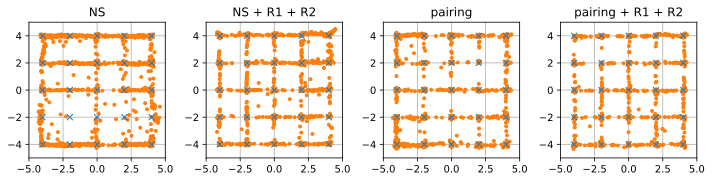

In [13]:
fig, axes = d2l.plt.subplots(1, 4, figsize=(10, 2.9))
for ax, name in zip(axes, list(runs)[:4]):
    x = runs[name][0][0][:3000]               # run 0; centers drawn last
    d2l.plot([x[:, 0], grid[:, 0]], [x[:, 1], grid[:, 1]],
             fmts=('C1.', 'C0x'), xlim=(-5, 5), ylim=(-5, 5), axes=ax)
    ax.set_title(name)
    ax.set_aspect('equal')
fig.tight_layout()

<!-- d2l:prose id=convergence-md-15 fw=all -->

The results isolate the roles of the gradient penalties and the pairing loss:

- **Gradient penalties drive mode coverage:** Without penalties ($\gamma = 0$), critic gradients remain steep ($\mathbb{E}_q\|\nabla_x D\|^2 \in [0.7, 17]$) and mode coverage is unreliable (dropping to 12–25 modes depending on the seed). With $R_1 + R_2$ at $\gamma = 1$, critic gradients are damped by three orders of magnitude ($\sim 10^{-3}$) and every run covers all 25 modes under both `NS` and `pairing`.
- **Overdamping at large $\gamma$:** Increasing $\gamma$ to $10$ over-flattens the critic ($\sim 10^{-4}$), slowing convergence so that only 20–30% of samples land within $3\sigma$ of a mode after 10,000 steps.

Finally, inspecting the checkpoint traces shows why a calm critic loss curve must be interpreted with care:

In [14]:
traces = {name: np.array(results[0][1]) for name, results in runs.items()}
for col, stat in enumerate(['on-mode fraction', 'critic loss']):
    print(f'{stat} of run 0 at every 1,250 steps')
    for name, trace in traces.items():         # trace: (checkpoint, stat)
        print(f'  {name:28}', ' '.join(f'{v:4.2f}' for v in trace[:, col]))

on-mode fraction of run 0 at every 1,250 steps
  NS                           0.01 0.03 0.08 0.16 0.29 0.54 0.69 0.72
  NS + R1 + R2                 0.02 0.03 0.09 0.08 0.26 0.64 0.68 0.79
  pairing                      0.02 0.07 0.17 0.31 0.50 0.73 0.74 0.82
  pairing + R1 + R2            0.02 0.01 0.04 0.16 0.50 0.74 0.81 0.86
  pairing + R1 + R2, gamma=10  0.02 0.03 0.02 0.05 0.09 0.09 0.16 0.21
critic loss of run 0 at every 1,250 steps
  NS                           1.35 1.21 1.04 1.00 1.01 1.03 1.05 1.07
  NS + R1 + R2                 1.38 1.37 1.36 1.37 1.38 1.38 1.38 1.38
  pairing                      0.68 0.65 0.57 0.57 0.60 0.62 0.63 0.64
  pairing + R1 + R2            0.68 0.68 0.67 0.68 0.69 0.69 0.69 0.69
  pairing + R1 + R2, gamma=10  0.69 0.70 0.69 0.69 0.69 0.69 0.69 0.69


<!-- d2l:prose id=convergence-md-16 fw=all -->

In the penalized runs, the critic loss sits near its equilibrium value ($2\log 2 \approx 1.39$ for `NS`, $\log 2 \approx 0.69$ for `pairing`) from the very first checkpoint, even when only 1–3% of generated samples lie on a mode, because the gradient penalty keeps $D(x)$ small everywhere. An equilibrium critic loss indicates a flat critic, not necessarily a converged generator.

## Summary

On the two-parameter Dirac-GAN ($p = \delta_0, q_\theta = \delta_\theta, D_\psi(x) = \psi x$), continuous-time gradient flow orbits on circles of constant radius, simultaneous discrete steps spiral outward, and alternating discrete steps remain trapped in a bounded band. Subtracting the zero-centered gradient penalties $R_1 = \frac{\gamma}{2}\mathbb{E}_p[\|\nabla_x D(x)\|^2]$ and $R_2 = \frac{\gamma}{2}\mathbb{E}_q[\|\nabla_{x'} D(x')\|^2]$ shifts the Jacobian eigenvalues into the open left half-plane ($\operatorname{Re}(\nu_{1,2}) < 0$) for every $\gamma > 0$, rendering the equilibrium locally exponentially stable. Near equilibrium, $R_1 + R_2$ acts as a spatial low-pass filter on $p - q$ with cutoff length scale $2\sqrt{\gamma}$ under the logistic loss, interpolating between $2\,\mathrm{JS}(p, q)$ at large scales and the squared dual Sobolev norm $\|p - q\|_{\dot H^{-1}(m)}^2$ at fine scales. Empirically, on the 25-Gaussian grid, $R_1 + R_2$ at $\gamma = 1$ damps critic steepness by three orders of magnitude and yields full mode coverage under both classic logistic and relativistic pairing objectives.

## Exercises

1. [code] **Discrete-time stability of the Dirac-GAN.** Simultaneous gradient descent with step size $h$ maps $(\theta, \psi) \mapsto (\theta, \psi) + h\,\mathbf{u}(\theta, \psi)$.
    1. Show that at $\gamma = 0$, the Jacobian of the discrete update at $(0, 0)$ has eigenvalues $1 \pm i\,h\,\ell'(0)$, which have modulus $\sqrt{1 + h^2\ell'(0)^2} > 1$ for every $h > 0$.
    1. For $\gamma > 0$, the eigenvalues are $1 + h\nu_{1,2}$ with $\nu_{1,2}$ from the equation. Show that in the underdamped regime $\gamma < 2\ell'(0)$, the discrete update is locally stable ($|1 + h\nu_{1,2}| < 1$) if and only if $h < \gamma / \ell'(0)^2$.
    1. Verify this threshold at $\gamma = 0.3$ ($\ell'(0) = \tfrac12$, threshold $h = 1.2$) by running `trajectory(euler_step, (0.1, 0.1), h, 3000, gamma=0.3)` at $h = 1.1$ and $h = 1.3$.

1. **Penalized best response on the Dirac-GAN.** Consider $V_\gamma(\theta) = \sup_\psi \{V(\theta, \psi) - \gamma\psi^2\}$ on the Dirac-GAN with $\ell = \log \sigma$.
    1. Show that for small $\theta$, the maximizing slope is $\psi^\star \approx -\ell'(0)\theta / (2\gamma)$ and $V_\gamma(\theta) = 2\ell(0) + \frac{\ell'(0)^2}{4\gamma}\theta^2 + O(\theta^4)$, matching the equation with $W_2(\delta_0, \delta_\theta) = |\theta|$.
    1. Now let $D$ range over all differentiable functions penalized by $\gamma\int m\,\|\nabla_x D\|^2$. Show that for point masses $p = \delta_0$ and $q_\theta = \delta_\theta$ ($\theta \neq 0$), $\sup_D \{V_\ell(D) - R_1 - R_2\} = 2\sup_t \ell(t)$ is independent of $\theta$. Why does a finite neural network critic still provide a nonzero gradient across the gap?

1. **Penalizing $R_1$ alone versus $R_1 + R_2$.** Let $p = \delta_0$, $q = \delta_1$, $\ell = \log \sigma$, and consider the quadratic critics $D_c(x) = -cx^2$ ($c \geq 0$).
    1. Evaluate $R_1$ and $R_2$ for $D_c$, and show that $V_\ell(D_c) - R_1$ is strictly increasing in $c$, so it has no finite maximizer.
    1. Show that under the non-saturating generator loss $-\log \sigma(D_c(x'))$, the generator gradient magnitude at $x' = 1$ grows unboundedly with $c$, whereas subtracting $R_1 + R_2$ yields a finite maximizer $c^\star < 1/(8\gamma)$.

1. [code] **Alternating updates on the Dirac-GAN.** ● Alternating updates apply $\psi_{k+1} = \psi_k + h\,u_\psi(\theta_k, \psi_k)$ followed by $\theta_{k+1} = \theta_k + h\,u_\theta(\theta_k, \psi_{k+1})$.
    1. Linearize the combined update at $(0, 0)$ for $\gamma = 0$ and show that its Jacobian has determinant $1$, with eigenvalues on the unit circle if and only if $h\,\ell'(0) \leq 2$.
    1. Run `trajectory(alt_step, (0.1, 0.1), h, 10**5)` at $\gamma = 0$ for $h \in \{0.2, 1, 3, 5\}$, record the minimum and maximum radius over the final $10^4$ steps, and compare with $\gamma = 0.3$ at $h = 0.2$.

1. [code] **Local quadratic value and low-pass filtering.** ● Write $\mathcal{A} = |\ell''(0)|\,m + \gamma\mathcal{L}_m$ with $\mathcal{L}_m D = -\nabla \cdot (m \nabla D)$.
    1. Using integration by parts, show that

       $$|\ell''(0)|\int m\,D^2 + \gamma\int m\,\|\nabla_x D\|^2 = \langle D, \mathcal{A}D \rangle$$

       and derive the equation by maximizing along rays $t D_0$ and applying Cauchy–Schwarz.
    1. Let $p = \mathcal{N}(0, 1)$ and $q(x) = p(x)(1 + 0.1\sin(\omega x))$. Using `penalized_value`, compute the ratio of the penalized value at $\gamma \in \{0.01, 0.1, 1\}$ to the unpenalized value at $\gamma = 0$ for $\omega \in \{0.5, 2, 8\}$, and compare against the uniform-$m$ Fourier attenuation factor $(1 + 4\gamma\omega^2)^{-1}$.

1. [code] **One-centered penalty dynamics on the Dirac-GAN.** ● Consider the WGAN linear payoff $\ell(t) = t$ ($\ell'(0) = 1$) with the one-centered penalty $\frac{\gamma}{2}(|\psi| - 1)^2$ subtracted from the critic objective.
    1. Show that the simultaneous gradient field never vanishes for $\psi \neq 0$, and find the generator positions $\theta$ where its one-sided limits as $\psi \to 0^\pm$ vanish.
    1. Modify `dirac_field` to use the one-centered penalty and run `trajectory` from $(1, 1)$ with $h = 0.01$ for 40,000 steps at $\gamma = 1$ and $\gamma = 3$, verifying that at $\gamma = 3$ the generator stalls at $\theta = 3$.

[Discussions](https://d2l.discourse.group/t/36811)